# Customer Churn Prediction with Logistic Regression

**Topic:** Binary classification · **Dataset:** Bank customers (`Churn_Modelling.csv`, 10,000 rows)

## The business problem
A bank is losing customers. A customer who closes their account is called a **churned** customer.
Keeping an existing customer is much cheaper than finding a new one, so the bank wants to know
**which customers are likely to leave**, before they actually leave.

## The machine learning task
- **Target (y):** `Exited` → **1** = the customer left the bank, **0** = the customer stayed.
- Because the target has only two values, this is a **binary classification** problem.
- **Model:** Logistic Regression.

## Notebook structure
1. Setup and data loading
2. Data understanding and cleaning
3. Exploratory Data Analysis (EDA)
4. Preprocessing: encoding and train/test split
5. Training a Logistic Regression model
6. Evaluation: accuracy, confusion matrix, precision, recall, F1
7. Improving the model: feature scaling and threshold tuning
8. Business output: the list of customers at risk
9. Conclusions

## 1. Setup and data loading
We import the libraries we need. Each import has a short comment that explains what it is used for.

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Machine learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Display settings: show all columns, keep row output short
pd.options.display.max_columns = None
pd.options.display.max_rows = 100
sns.set_theme(style="whitegrid")

In [2]:
# Load the dataset directly from GitHub
url = "https://raw.githubusercontent.com/HumayDS/Big-data-analysis/main/Churn_Modelling.csv"
df = pd.read_csv(url)

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (10000, 15)


,Unnamed: 0,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2,3,15619304,Onio,502,NaN,Female,42,8,159660.80,3,1,0,113931.57,1
3,3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2. Data understanding and cleaning

### 2.1 How many unique values does each column have?
This quickly shows which columns are **identifiers** (every value is different),
which are **categorical** (few values) and which are **numerical** (many values).

In [3]:
df.nunique()

Unnamed: 0         10000
RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

**Insight:** `Unnamed: 0`, `RowNumber` and `CustomerId` have 10,000 unique values, one per row.
They are just IDs, so they cannot help the model predict churn. `Surname` is also not useful
(and using names could even introduce unfair bias). We will drop these four columns.

Before dropping `CustomerId`, we **save it in a separate variable**. At the end of the notebook
we will need it to tell the bank *which* customers are at risk.

In [4]:
# Keep the customer IDs aside; the row index lets us match them later
customer_id = df["CustomerId"]

# Drop columns that carry no predictive information
df = df.drop(["Unnamed: 0", "RowNumber", "CustomerId", "Surname"], axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        9999 non-null   str    
 2   Gender           9999 non-null   str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


### 2.2 Missing values
We check missing values both as **counts** and as **percentages**.

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(3),
})
missing[missing["missing_count"] > 0]

,missing_count,missing_percent
Geography,1,0.01
Gender,1,0.01


**Insight:** only `Geography` and `Gender` have missing values, and just **one row each** (0.01%).
Both are categorical, so we fill them with the **mode** (the most frequent value).
With so few missing values, this choice has almost no effect on the results.

In [6]:
# Fill categorical columns with their most frequent value (mode)
for col in ["Gender", "Geography"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check: there should be no missing values left
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


In [7]:
# Save the cleaned dataset (useful if we want to reuse it later)
df.to_csv("df_clean.csv", index=False)

### 2.3 Descriptive statistics

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
HasCrCard,10000.0,0.705500,0.455840,0.00,0.00,1.000,1.0000,1.00
IsActiveMember,10000.0,0.515100,0.499797,0.00,0.00,1.000,1.0000,1.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48
Exited,10000.0,0.203700,0.402769,0.00,0.00,0.000,0.0000,1.00


**Insights:**
- `Age` ranges from 18 to 92, with a mean of about 39.
- `Balance` has many zeros (the 25th percentile is 0): a large group of customers keep no money in the account.
- `NumOfProducts` is between 1 and 4; most customers have 1 or 2 products.
- `HasCrCard`, `IsActiveMember` and `Exited` are already coded as **0/1**.
- The mean of `Exited` is about **0.20** → around **20% of customers left the bank**.

## 3. Exploratory Data Analysis (EDA)

### 3.1 How balanced is the target?

Exited
0    7963
1    2037
Name: count, dtype: int64

Share of each class:
 Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


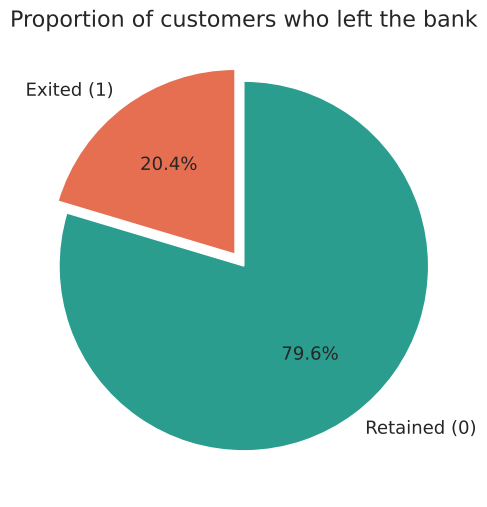

In [9]:
churn_counts = df["Exited"].value_counts()
print(churn_counts)
print("\nShare of each class:\n", df["Exited"].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(figsize=(7, 6))
ax.pie([churn_counts[1], churn_counts[0]], labels=["Exited (1)", "Retained (0)"],
       explode=(0.08, 0), autopct="%1.1f%%", startangle=90,
       colors=["#E76F51", "#2A9D8F"], textprops={"fontsize": 13})
ax.set_title("Proportion of customers who left the bank", size=16)
plt.show()

**Insight: the classes are imbalanced.** About **20%** of customers churned and **80%** stayed.

This is very important for evaluation. A "lazy" model that predicts *"nobody will leave"* would already
have about **80% accuracy**, while finding **zero** churners. So later we must **not** judge our model by accuracy alone.
We will also look at **precision, recall and F1** for class 1.

### 3.2 Churn rate by categorical features
To avoid repeating the same code four times, we write a small helper function.
For each group it shows: the number of customers (`count`), how many left (`churned`), and the **churn rate** (`churn_rate`).

In [10]:
def churn_rate(column):
    # Churn statistics for each value of a column
    table = df.groupby(column)["Exited"].agg(count="count", churned="sum")
    table["churn_rate"] = (table["churned"] / table["count"]).round(3)
    return table

for col in ["Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts"]:
    print(f"--- {col} ---")
    print(churn_rate(col), "\n")

--- Geography ---
           count  churned  churn_rate
Geography                            
France      5014      810       0.162
Germany     2509      814       0.324
Spain       2477      413       0.167 

--- Gender ---
        count  churned  churn_rate
Gender                            
Female   4542     1139       0.251
Male     5458      898       0.165 

--- HasCrCard ---
           count  churned  churn_rate
HasCrCard                            
0           2945      613       0.208
1           7055     1424       0.202 

--- IsActiveMember ---
                count  churned  churn_rate
IsActiveMember                            
0                4849     1302       0.269
1                5151      735       0.143 

--- NumOfProducts ---
               count  churned  churn_rate
NumOfProducts                            
1               5084     1409       0.277
2               4590      348       0.076
3                266      220       0.827
4                 60       60   

> **Note:** in the original notebook the `IsActiveMember` table accidentally used the `HasCrCard` numbers
> (`am['Perc'] = cr['sum'] / cr['count']`). The helper function above fixes this, and the real numbers tell a very different story.

**Insights:**
- **Geography:** customers in **Germany** leave about **twice as often** (≈32%) as customers in France or Spain (≈16–17%).
- **Gender:** **women** churn more often (≈25%) than men (≈16%).
- **HasCrCard:** almost **no difference** (≈20% in both groups) → having a credit card does not seem to matter.
- **IsActiveMember:** **inactive** customers churn about **twice as often** (≈27%) as active ones (≈14%).
- **NumOfProducts:** customers with **2 products** are the most loyal (≈8%). Customers with **3 or 4 products** churn at a very high rate (≈83% and 100%), although these groups are small.

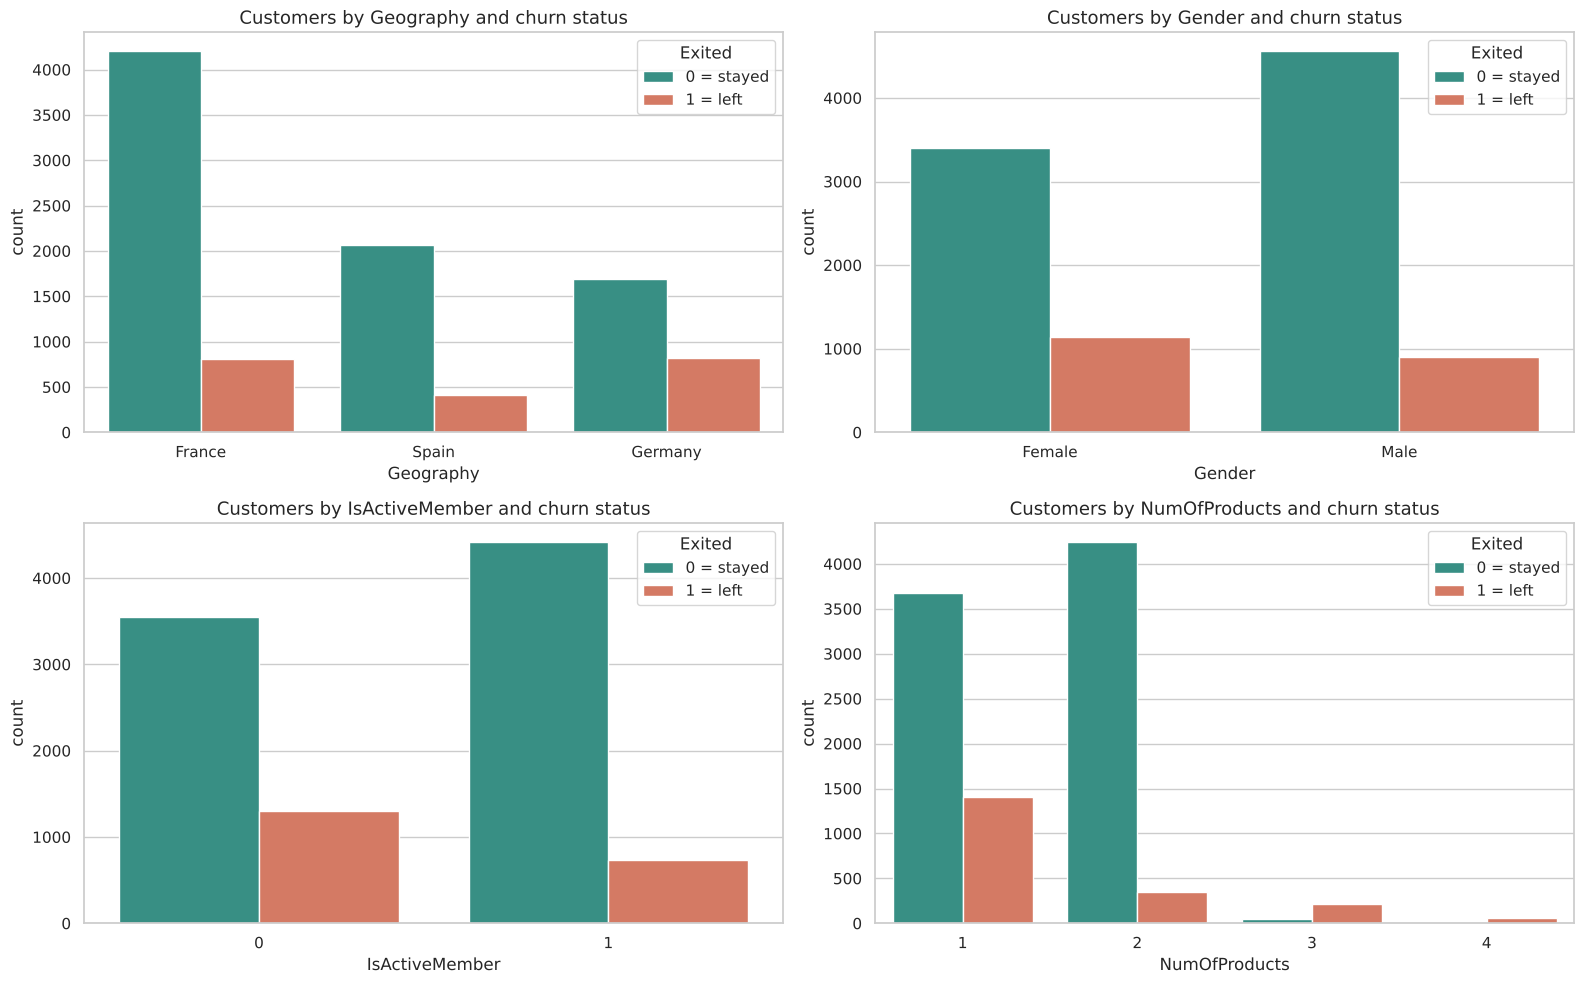

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.ravel(), ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]):
    sns.countplot(x=col, hue="Exited", data=df, ax=ax, palette=["#2A9D8F", "#E76F51"])
    ax.set_title(f"Customers by {col} and churn status", size=13)
    ax.legend(title="Exited", labels=["0 = stayed", "1 = left"])
plt.tight_layout()
plt.show()

### 3.3 Numerical features vs churn
Box plots compare the distribution of a numerical feature for customers who stayed (0) and who left (1).

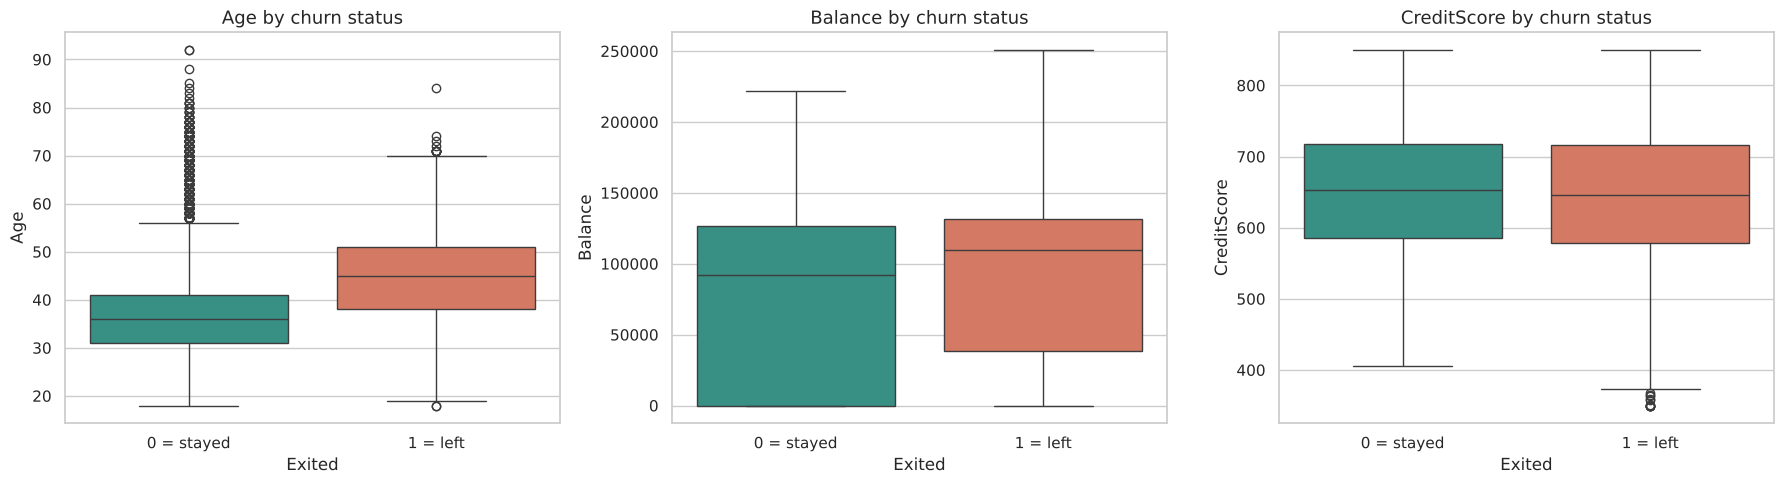

,Age,Balance,CreditScore,EstimatedSalary
Exited,,,,
0,36.0,92072.68,653.0,99645.04
1,45.0,109349.29,646.0,102460.84


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Age", "Balance", "CreditScore"]):
    sns.boxplot(x="Exited", y=col, data=df, ax=ax, palette=["#2A9D8F", "#E76F51"], hue="Exited", legend=False)
    ax.set_title(f"{col} by churn status", size=13)
    ax.set_xticks([0, 1], ["0 = stayed", "1 = left"])
plt.tight_layout()
plt.show()

df.groupby("Exited")[["Age", "Balance", "CreditScore", "EstimatedSalary"]].median()

**Insights:**
- **Age is the clearest signal:** the median age of customers who left is about **45**, compared with **36** for those who stayed.
- Customers who left have a somewhat **higher balance** on average.
- `CreditScore` and `EstimatedSalary` look almost the **same** in both groups, so they are probably weak predictors.

**EDA summary:** the profile of a customer at risk is roughly *older, from Germany, female, not active, with only one product (or 3–4 products)*.

## 4. Preprocessing

### 4.1 One-hot encoding of categorical variables
Machine learning models work with numbers, not text. `Geography` and `Gender` are text columns,
so we turn them into **dummy (0/1) columns**.

We use `drop_first=True` to avoid redundant columns: for example, if a customer is not from Germany and not from Spain,
they must be from France, so a separate `Geography_France` column is not needed.

In [13]:
# Find the text (categorical) columns
categorical_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Categorical columns:", categorical_cols)

# Create dummy variables and replace the original text columns
df_dummies = pd.get_dummies(df[categorical_cols], drop_first=True, dtype=int)
df = pd.concat([df.drop(columns=categorical_cols), df_dummies], axis=1)
df.head()

Categorical columns: ['Geography', 'Gender']


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


### 4.2 Define X and y, then split into train and test sets
- **X** = all features, **y** = the target `Exited`.
- **70%** of the rows are used for training, **30%** for testing.
- `stratify=y` keeps the **same 20/80 churn ratio** in both sets. This is important because the classes are imbalanced.
- `random_state=42` makes the split reproducible.

In [14]:
y = df["Exited"]
X = df.drop(columns=["Exited"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,      # 30% of the data for testing
    random_state=42,     # same split every time we run the notebook
    stratify=y,          # keep the same share of churners in train and test
)

print("Train set:", X_train.shape, "| churn rate:", round(y_train.mean(), 3))
print("Test set: ", X_test.shape, "| churn rate:", round(y_test.mean(), 3))

Train set: (7000, 11) | churn rate: 0.204
Test set:  (3000, 11) | churn rate: 0.204


## 5. Training a Logistic Regression model
Logistic regression calculates the **probability** that a customer will leave.
If the probability is **0.5 or higher**, it predicts **1** (will leave); otherwise **0** (will stay).

We train the model **only on the training set**.

In [15]:
log_model = LogisticRegression(solver="liblinear")
log_model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [16]:
# Predicted classes (0 or 1)
pred_train = log_model.predict(X_train)
pred_test = log_model.predict(X_test)

# Predicted probability of class 1 (churn)
proba_test = log_model.predict_proba(X_test)[:, 1]

# Look at the first 10 test customers: real class, predicted probability and predicted class
pd.DataFrame({
    "real": y_test.values[:10],
    "prob_churn": proba_test[:10].round(3),
    "predicted": pred_test[:10],
})

,real,prob_churn,predicted
0,0,0.076,0
1,0,0.307,0
2,0,0.147,0
3,0,0.099,0
4,0,0.275,0
5,0,0.445,0
6,0,0.231,0
7,0,0.352,0
8,0,0.242,0
9,0,0.147,0


**Insight:** most predicted probabilities are well **below 0.5**, so the model predicts "0 = stays" for almost everyone.
We will see the effect of this in the evaluation.

## 6. Evaluation

### 6.1 Accuracy on train and test, compared with a baseline
The **baseline** is the accuracy of a model that always predicts the most common class (0 = stays).
A useful model must be clearly better than this baseline.

In [17]:
baseline = 1 - y_test.mean()  # accuracy of always predicting 0

print(f"Baseline accuracy (always predict 0): {baseline:.3f}")
print(f"Train accuracy:                       {accuracy_score(y_train, pred_train):.3f}")
print(f"Test accuracy:                        {accuracy_score(y_test, pred_test):.3f}")

Baseline accuracy (always predict 0): 0.796
Train accuracy:                       0.789
Test accuracy:                        0.795


**Insights:**
- Train and test accuracy are **very close**, so there is **no overfitting**.
- But the test accuracy is **almost the same as the baseline**. The model is hardly better than simply saying *"nobody leaves"*.
  This is a sign of **underfitting**: the model has not learned the churn pattern well.
- Accuracy alone cannot show us what is going wrong. We need the confusion matrix.

### 6.2 Confusion matrix
Rows = **real** class, columns = **predicted** class.

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN (correct) | FP (false alarm) |
| **Actual 1** | FN (missed churner) | TP (churner found) |

TN: 2352   FP: 37   FN: 578   TP: 33


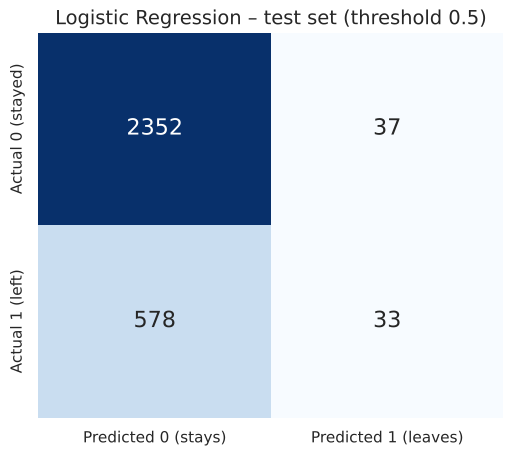

In [18]:
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()
print(f"TN: {tn}   FP: {fp}   FN: {fn}   TP: {tp}")

def plot_cm(cm, title):
    # Heatmap of a confusion matrix with readable labels
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 16},
                xticklabels=["Predicted 0 (stays)", "Predicted 1 (leaves)"],
                yticklabels=["Actual 0 (stayed)", "Actual 1 (left)"])
    plt.title(title, size=14)
    plt.show()

plot_cm(cm, "Logistic Regression – test set (threshold 0.5)")

### 6.3 Precision, recall and F1 – calculated by hand and checked with scikit-learn

In [19]:
precision = tp / (tp + fp)   # when the model says "leaves", how often is it right?
recall    = tp / (tp + fn)   # of all customers who really left, how many did we find?
f1        = 2 * precision * recall / (precision + recall)

print(f"Precision = {tp} / ({tp} + {fp}) = {precision:.3f}")
print(f"Recall    = {tp} / ({tp} + {fn}) = {recall:.3f}")
print(f"F1 score  = {f1:.3f}")

# The same numbers from scikit-learn
print("\nClassification report (test set):\n")
print(classification_report(y_test, pred_test, digits=3))

Precision = 33 / (33 + 37) = 0.471
Recall    = 33 / (33 + 578) = 0.054
F1 score  = 0.097

Classification report (test set):

              precision    recall  f1-score   support

           0      0.803     0.985     0.884      2389
           1      0.471     0.054     0.097       611

    accuracy                          0.795      3000
   macro avg      0.637     0.519     0.491      3000
weighted avg      0.735     0.795     0.724      3000



**Insights – this is the key result of the basic model:**
- **Recall for class 1 is only about 5%.** Out of about 611 customers who really left, the model found only about 33.
  More than **570 churners were missed** (false negatives).
- For the bank, a missed churner is the **expensive** mistake: the customer leaves and nobody tried to keep them.
- The **80% accuracy is misleading**: it comes almost entirely from correctly predicting the 0s (customers who stay).

**Why does this happen?**
1. The classes are imbalanced (80/20), so the model learns that predicting "stays" is usually right.
2. The features have **very different scales** (`Balance` up to 250,000, `Age` up to 92, dummy columns 0/1).
   Logistic regression learns poorly when features are not scaled.
3. The default threshold of 0.5 is too high for a rare class.

In the next section we fix points 2 and 3.

## 7. Improving the model

### 7.1 Feature scaling with a Pipeline
`StandardScaler` puts every feature on the same scale (mean 0, standard deviation 1).

We use a **Pipeline**, so the scaler is **fitted on the training set only** and then applied to the test set.
This avoids **data leakage** (the test set must stay unseen during training).

In [20]:
scaled_model = make_pipeline(StandardScaler(), LogisticRegression())
scaled_model.fit(X_train, y_train)

def evaluate(model_name, y_true, y_pred):
    # One row of metrics for the comparison table
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate("Basic LR – train",  y_train, pred_train),
    evaluate("Basic LR – test",   y_test,  pred_test),
    evaluate("Scaled LR – train", y_train, scaled_model.predict(X_train)),
    evaluate("Scaled LR – test",  y_test,  scaled_model.predict(X_test)),
]).set_index("model").round(3)
results

,accuracy,precision,recall,f1
model,,,,
Basic LR – train,0.789,0.360,0.045,0.080
Basic LR – test,0.795,0.471,0.054,0.097
Scaled LR – train,0.812,0.617,0.201,0.304
Scaled LR – test,0.813,0.628,0.196,0.299


**Insights:**
- Only by scaling the features, **recall rises from about 5% to about 20%** and **precision from about 0.47 to about 0.63**. F1 triples.
- Train and test scores are still close → still **no overfitting**.
- But recall is still low: the model still misses about 4 out of 5 churners. The next step is the threshold.

### 7.2 Which features matter most?
With scaled features, the size of a logistic regression **coefficient** shows how strongly a feature affects churn.
- **Positive** coefficient → increases the probability of leaving.
- **Negative** coefficient → decreases it.

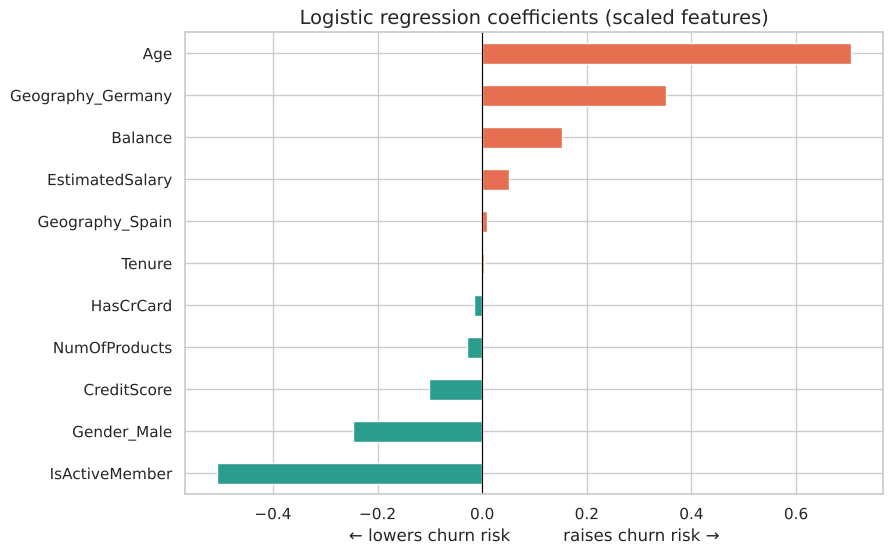

In [21]:
coefs = pd.Series(scaled_model[-1].coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(9, 6))
coefs.plot(kind="barh", color=["#2A9D8F" if c < 0 else "#E76F51" for c in coefs])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression coefficients (scaled features)", size=14)
plt.xlabel("← lowers churn risk          raises churn risk →")
plt.show()

**Insights:** the model confirms what we saw in the EDA.
- **Age** is the strongest factor: older customers are more likely to leave.
- Being from **Germany** and having a higher **balance** increase the risk.
- Being an **active member** and being **male** decrease the risk.
- `HasCrCard`, `Tenure` and `EstimatedSalary` have almost no effect.

Note: logistic regression only finds straight-line (linear) effects. It cannot see, for example, that customers with
2 products are loyal but customers with 3–4 products are not. More flexible models can learn such patterns.

### 7.3 Threshold tuning
By default, a customer is predicted as "leaves" if the probability is at least **0.5**.
If we **lower the threshold**, we catch more churners (**recall goes up**), but we also create more false alarms (**precision goes down**).

To keep the test set honest, we **choose the threshold on the training set**, then check it **once** on the test set.

Best threshold on the training set (highest F1): 0.25


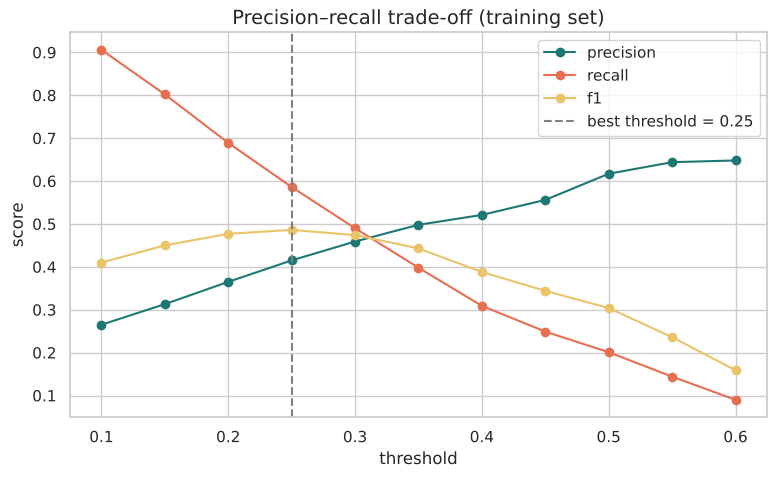

,precision,recall,f1
threshold,,,
0.10,0.265,0.906,0.410
0.15,0.313,0.802,0.450
0.20,0.365,0.689,0.477
0.25,0.415,0.586,0.486
0.30,0.459,0.490,0.474
0.35,0.498,0.398,0.443
0.40,0.521,0.309,0.388
0.45,0.556,0.249,0.344
0.50,0.617,0.201,0.304


In [22]:
proba_train_s = scaled_model.predict_proba(X_train)[:, 1]
proba_test_s = scaled_model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.10, 0.61, 0.05).round(2)
rows = []
for t in thresholds:
    p = (proba_train_s >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_train, p),
                 "recall": recall_score(y_train, p),
                 "f1": f1_score(y_train, p)})
thr_table = pd.DataFrame(rows).set_index("threshold").round(3)

best_t = thr_table["f1"].idxmax()
print("Best threshold on the training set (highest F1):", best_t)

thr_table.plot(figsize=(9, 5), marker="o", color=["#1D7874", "#E76F51", "#E9C46A"])
plt.axvline(best_t, color="grey", linestyle="--", label=f"best threshold = {best_t}")
plt.title("Precision–recall trade-off (training set)", size=14)
plt.ylabel("score"); plt.legend(); plt.show()

thr_table

**Insight:** as the threshold goes down, recall rises and precision falls, exactly the trade-off from the lecture.
F1 is highest at a threshold of about **0.25**, much lower than the default 0.5.

,accuracy,precision,recall,f1
model,,,,
Basic LR – train,0.789,0.360,0.045,0.080
Basic LR – test,0.795,0.471,0.054,0.097
Scaled LR – train,0.812,0.617,0.201,0.304
Scaled LR – test,0.813,0.628,0.196,0.299
Scaled LR + threshold 0.25 – test,0.768,0.450,0.625,0.523


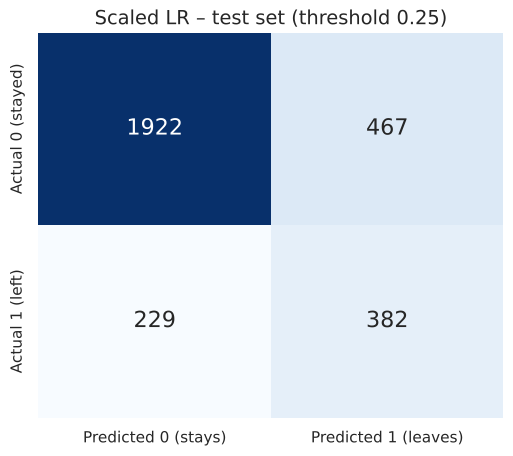

In [23]:
# Apply the chosen threshold to the test set (one final check)
pred_test_tuned = (proba_test_s >= best_t).astype(int)

results.loc[f"Scaled LR + threshold {best_t} – test"] = pd.Series(
    evaluate("", y_test, pred_test_tuned)).drop("model").astype(float).round(3)
display(results)

plot_cm(confusion_matrix(y_test, pred_test_tuned),
        f"Scaled LR – test set (threshold {best_t})")

**Insights:**
- With the tuned threshold, **recall on the test set is about 62%**: the model now finds most of the churners, instead of 1 in 20.
- **F1 rises from about 0.10 (basic model) to about 0.52.**
- The price: precision drops to about 0.45, so more than half of the flagged customers would not really leave,
  and accuracy goes down a little (to about 77%).
- For a bank this is usually a good trade: contacting a loyal customer with a special offer is cheap,
  while losing a customer is expensive. The best threshold always depends on these business costs.

## 8. Business output: customers at risk
We give the bank a list of test-set customers that the final model predicts will leave,
sorted by churn probability (highest risk first). The `CustomerId` values we saved at the beginning
are matched through the row index.

In [24]:
at_risk = pd.DataFrame({
    "CustomerId": customer_id.loc[X_test.index],
    "churn_probability": proba_test_s.round(3),
    "predicted": pred_test_tuned,
    "actually_left": y_test,
})
at_risk = at_risk[at_risk["predicted"] == 1].sort_values("churn_probability", ascending=False)

print("Number of customers flagged as at risk:", len(at_risk))
at_risk.head(10)

Number of customers flagged as at risk: 849


,CustomerId,churn_probability,predicted,actually_left
3531,15653251,0.915,1,1
9747,15775761,0.867,1,1
7008,15638610,0.844,1,1
617,15766575,0.833,1,1
2473,15679249,0.829,1,1
3387,15798024,0.821,1,0
416,15720559,0.813,1,1
6530,15808851,0.809,1,0
7636,15673238,0.804,1,1
3991,15601659,0.791,1,1


In [25]:
# Save the list so the bank can use it (for example, for a retention campaign)
at_risk.to_csv("churn_customers.csv", index=False)

## 9. Conclusions

### What we learned about the customers
- About **20%** of customers left the bank → the data is **imbalanced**.
- The strongest churn signals are **age** (older customers leave more), **Germany**, **inactivity**,
  **gender** (women leave more) and the **number of products** (1, 3 or 4 products = higher risk; 2 products = most loyal).
- Having a credit card, tenure and salary have almost no relation to churn.

### What we learned about the model
| Model (test set) | Accuracy | Recall (class 1) | F1 (class 1) |
|---|---|---|---|
| Basic logistic regression | ≈ 0.80 | ≈ 0.05 | ≈ 0.10 |
| + feature scaling | ≈ 0.81 | ≈ 0.20 | ≈ 0.30 |
| + scaling and threshold ≈ 0.25 | ≈ 0.77 | ≈ 0.62 | ≈ 0.52 |

*(Exact values are in the tables above.)*

- **Accuracy was misleading.** The basic model reached 80% accuracy, but it found only about 5% of the churners,
  almost the same as a model that always predicts "stays".
- **Recall and F1** showed the real problem, and the confusion matrix explained it: hundreds of false negatives.
- **Scaling the features** and **lowering the threshold** turned an almost useless model into one that finds most churners.
- Train and test scores stayed close in every step → **no overfitting**. The remaining weakness is closer to
  **underfitting**: a linear model cannot capture some patterns (for example, the effect of 3–4 products).

### Possible next steps
- Try more flexible models such as decision trees and ensemble methods (coming in the next lessons).
- Try `class_weight="balanced"` in logistic regression, another way to deal with imbalanced classes.
- Create new features, for example `Balance == 0` or age groups.
- Choose the threshold together with the business team, based on the real cost of a missed churner versus a false alarm.